<a href="https://colab.research.google.com/github/dhvani0506/rnn-cifar10-audiomnist/blob/main/RNN_Dhvani.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Recurrent Neural Networks on Images and Audio
### Midterm Project, Topic 3: CIFAR-10 RNN analysis and an Audio MNIST LSTM classifier

Dhvani Patel


This notebook asks one question: *how does a recurrent network process sequential data, and how does the same architecture behave on two very different kinds of input?*

| | CIFAR-10 | Audio MNIST |
|---|---|---|
| Raw input | 32×32 RGB image | ≈0.5–1 s spoken digit (48 kHz WAV) |
| One time step | one row of pixels (32 px × 3 channels = 96 values) | one ~10 ms audio frame (40 MFCC / mel values) |
| Sequence length | always 32 | varies (~35–100 frames) |
| Is the order "real"? | no, top-to-bottom is an arbitrary choice | yes, speech unfolds in time |
| Classes | 10 object categories | digits 0–9 |

**Contents**
1. Setup
2. Part A: CIFAR-10 as a sequence (data → model → loss → training → evaluation)
3. Part B: Audio MNIST (download → features → speaker-based split → LSTM)
4. Experiments: vanilla RNN vs LSTM vs GRU, and hidden size
5. Vanishing gradients, measured directly
6. Comparison and discussion

## 1. Setup

Run this notebook on **Google Colab** with a GPU runtime (Runtime → Change runtime type → GPU). Google Drive is mounted so that datasets, cached features, figures and saved models persist between sessions; everything is written under `PROJECT_DIR` on Drive.

All required packages (torch, torchvision, librosa, scikit-learn, matplotlib, tqdm) are pre-installed on Colab.

**Run the cells in order, top to bottom.** The first run is slow (CIFAR-10 download, ~1 GB Audio MNIST clone, MFCC extraction); later sessions reuse the files on Drive.

In [ ]:
import os, glob, time, copy, random, subprocess
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split
from torch.nn.utils.rnn import pack_padded_sequence
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
try:
    from tqdm.auto import tqdm
except ImportError:                      # progress bars are optional
    def tqdm(it, **kwargs): return it

# ---------------- Google Drive (Colab) ----------------
# Mount Drive so data, cached features, figures and models survive runtime resets.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    os.environ.setdefault("PROJECT_DIR", "/content/drive/MyDrive/rnn_midterm")
except ImportError:
    pass                                  # not on Colab: fall back to ~/rnn_midterm

# ---------------- configuration ----------------
PROJECT_DIR = Path(os.environ.get("PROJECT_DIR", Path.home() / "rnn_midterm"))
DATA_DIR    = PROJECT_DIR / "data"
FIG_DIR     = PROJECT_DIR / "figures"
for d in (DATA_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

SEED          = 42
BATCH_SIZE    = 128
LR            = 1e-3
CIFAR_EPOCHS  = 15     # RNNs on CIFAR plateau slowly; 15 is enough to see the trend
AUDIO_EPOCHS  = 25
GRAD_CLIP     = 1.0    # guards against exploding gradients in BPTT
NUM_WORKERS   = 2

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device)
print("PROJECT_DIR:", PROJECT_DIR)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Mounted at /content/drive
PyTorch 2.11.0+cu130 | device: cuda
PROJECT_DIR: /content/drive/MyDrive/rnn_midterm
GPU: Tesla T4


### A shared model for both tasks

Both tasks use the **same** classifier so the comparison is fair. Only the input size changes (96 for CIFAR rows, 40 for audio frames).

At every time step $t$ a vanilla RNN updates its hidden state with the **same weights**:

$$h_t = \tanh(W_{xh}\,x_t + W_{hh}\,h_{t-1} + b)$$

This weight sharing is what *recurrence* means: the network is one cell applied over and over. After the last step, the final hidden state $h_T$ summarizes the whole sequence and a linear layer maps it to 10 class scores (logits).

LSTM and GRU replace the single `tanh` update with **gated** updates. The LSTM keeps a separate cell state $c_t$ that is updated *additively*:

$$c_t = f_t \odot c_{t-1} + i_t \odot \tilde c_t$$

The forget gate $f_t$ can stay close to 1, so information (and gradient) can pass through many steps without being repeatedly squashed. This is the key to Section 5.

For audio, clips have different lengths. Instead of letting the RNN read padding zeros, we use `pack_padded_sequence`, so each sequence stops at its true last frame and $h_T$ is taken at the real end of the word.

In [ ]:
class SeqClassifier(nn.Module):
    # Many-to-one recurrent classifier: read the sequence, classify from the final hidden state.
    def __init__(self, input_size, hidden_size=128, num_layers=1, num_classes=10,
                 rnn_type="lstm", dropout=0.0):
        super().__init__()
        rnn_cls = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[rnn_type]
        self.rnn_type = rnn_type
        self.rnn = rnn_cls(input_size, hidden_size, num_layers=num_layers, batch_first=True,
                           dropout=dropout if num_layers > 1 else 0.0)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x, lengths=None):
        # x: (batch, time, features); lengths: true sequence lengths (optional)
        if lengths is not None:
            x = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, h = self.rnn(x)
        if self.rnn_type == "lstm":
            h = h[0]               # LSTM returns (h_n, c_n)
        return self.fc(h[-1])      # final hidden state of the top layer -> logits

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

for t in ["rnn", "lstm", "gru"]:
    print(f"{t.upper():5s} hidden=128, input=96: {count_params(SeqClassifier(96, 128, rnn_type=t)):,} parameters")

RNN   hidden=128, input=96: 30,218 parameters
LSTM  hidden=128, input=96: 117,002 parameters
GRU   hidden=128, input=96: 88,074 parameters


### Training and evaluation helpers

**Loss.** `nn.CrossEntropyLoss` applies softmax to the 10 logits and takes the negative log-probability of the true class:

$$\mathcal{L} = -\log \frac{e^{z_y}}{\sum_{k=1}^{10} e^{z_k}}$$

It is 0 when the model puts all probability on the correct class and grows without bound as that probability goes to 0.

**Backpropagation through time (BPTT).** `loss.backward()` treats the unrolled network (one copy of the cell per time step, all sharing weights) as one deep feed-forward graph. The gradient for each shared weight is the **sum** of its gradients from every time step.

**Gradient clipping.** If the products of Jacobians across steps grow instead of shrink, gradients *explode*. `clip_grad_norm_` rescales them to a maximum norm, a standard fix for RNNs.

We keep the weights from the epoch with the best **validation** accuracy, and only touch the **test** set once at the end.

In [ ]:
def unpack_batch(batch):
    # Batches are (x, y) for CIFAR and (x, lengths, y) for audio.
    if len(batch) == 3:
        x, lengths, y = batch
        return x.to(device), lengths, y.to(device)
    x, y = batch
    return x.to(device), None, y.to(device)

def run_epoch(model, loader, criterion, optimizer=None, to_seq=None):
    train = optimizer is not None
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for batch in loader:
            x, lengths, y = unpack_batch(batch)
            if to_seq is not None:
                x = to_seq(x)
            logits = model(x, lengths)
            loss = criterion(logits, y)
            if train:
                optimizer.zero_grad()
                loss.backward()                                  # BPTT
                nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                optimizer.step()
            total_loss += loss.item() * y.size(0)
            correct    += (logits.argmax(1) == y).sum().item()
            n          += y.size(0)
    return total_loss / n, correct / n

def train_model(model, train_loader, val_loader, epochs, lr=LR, to_seq=None, name="model"):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc"]}
    best_acc, best_state = -1.0, None
    t0 = time.time()
    for ep in range(1, epochs + 1):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer, to_seq)
        vl, va = run_epoch(model, val_loader,   criterion, None,      to_seq)
        for k, v in zip(hist, (tl, ta, vl, va)):
            hist[k].append(v)
        if va > best_acc:
            best_acc, best_state = va, copy.deepcopy(model.state_dict())
        print(f"[{name}] epoch {ep:2d}/{epochs}  train loss {tl:.3f} acc {ta:.3f} | "
              f"val loss {vl:.3f} acc {va:.3f}")
    model.load_state_dict(best_state)
    hist["time_s"] = time.time() - t0
    hist["best_val_acc"] = best_acc
    return model, hist

@torch.no_grad()
def predict(model, loader, to_seq=None):
    model.eval()
    preds, labels = [], []
    for batch in loader:
        x, lengths, y = unpack_batch(batch)
        if to_seq is not None:
            x = to_seq(x)
        preds.append(model(x, lengths).argmax(1).cpu())
        labels.append(y.cpu())
    return torch.cat(preds).numpy(), torch.cat(labels).numpy()

def plot_history(hists, title, fname):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for name, h in hists.items():
        ep = range(1, len(h["train_loss"]) + 1)
        line, = axes[0].plot(ep, h["train_loss"], label=f"{name} train")
        axes[0].plot(ep, h["val_loss"], "--", color=line.get_color(), label=f"{name} val")
        axes[1].plot(ep, h["train_acc"], color=line.get_color(), label=f"{name} train")
        axes[1].plot(ep, h["val_acc"], "--", color=line.get_color(), label=f"{name} val")
    axes[0].set(title="Cross-entropy loss", xlabel="epoch", ylabel="loss")
    axes[1].set(title="Accuracy", xlabel="epoch", ylabel="accuracy")
    for ax in axes:
        ax.grid(alpha=0.3); ax.legend(fontsize=8)
    fig.suptitle(title); fig.tight_layout()
    fig.savefig(FIG_DIR / fname, dpi=150); plt.show()

def plot_confusion(y_true, y_pred, class_names, title, fname):
    cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45, values_format="d")
    ax.set_title(title); fig.tight_layout()
    fig.savefig(FIG_DIR / fname, dpi=150); plt.show()
    return cm

---
## 2. Part A: CIFAR-10 as a sequence

> **Note:** this section re-implements the approach of the class CIFAR-10 RNN notebook so the two tasks share one code path. When writing the report, compare against the class notebook and note any differences (for example, grayscale vs RGB rows, number of layers, optimizer, or epochs).

### 2.1 Data

CIFAR-10 has 50,000 training and 10,000 test images (32×32×3) in 10 classes. We hold out 5,000 training images for validation. Each channel is normalized with the dataset mean and standard deviation.

In [ ]:
import torchvision
import torchvision.transforms as T

CIFAR_CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
                 "dog", "frog", "horse", "ship", "truck"]
CIFAR_MEAN, CIFAR_STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
transform = T.Compose([T.ToTensor(), T.Normalize(CIFAR_MEAN, CIFAR_STD)])

cifar_full = torchvision.datasets.CIFAR10(DATA_DIR, train=True,  download=True, transform=transform)
cifar_test = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True, transform=transform)

n_val = 5000
cifar_train, cifar_val = random_split(cifar_full, [len(cifar_full) - n_val, n_val],
                                      generator=torch.Generator().manual_seed(SEED))

cifar_loaders = {
    "train": DataLoader(cifar_train, BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS),
    "val":   DataLoader(cifar_val,   BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS),
    "test":  DataLoader(cifar_test,  BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS),
}
print(f"train {len(cifar_train)} | val {len(cifar_val)} | test {len(cifar_test)}")

100%|██████████| 170M/170M [36:23<00:00, 78.1kB/s]


train 45000 | val 5000 | test 10000


### 2.2 Turning an image into a sequence

A batch arrives as `(batch, channels, height, width) = (B, 3, 32, 32)`. To read it row by row we:

1. `permute` to `(B, 32, 32, 3)`: height first, so the row index becomes the time axis;
2. `reshape` to `(B, 32, 96)`: flatten each row's 32 pixels × 3 colors into one 96-dim vector.

So the RNN sees **32 time steps of 96 numbers**, scanning the picture from top to bottom.

image batch: (128, 3, 32, 32) -> sequence batch: (128, 32, 96)


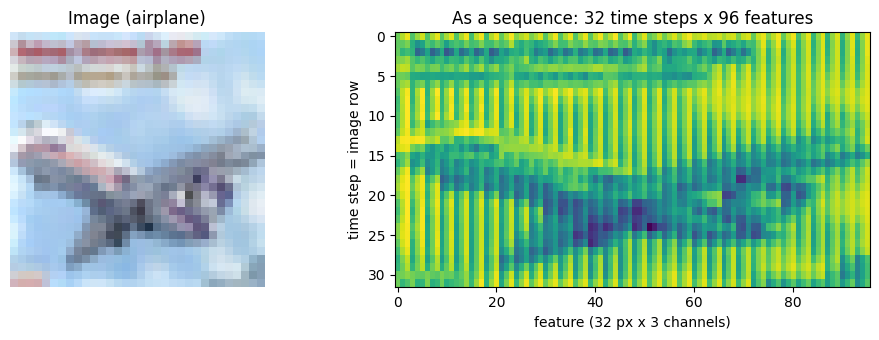

In [ ]:
def image_to_rows(x):
    # (B, C, H, W) -> (B, H, W*C): each image row becomes one time step.
    B, C, H, W = x.shape
    return x.permute(0, 2, 3, 1).reshape(B, H, W * C)

x0, y0 = next(iter(cifar_loaders["train"]))
seq0 = image_to_rows(x0)
print("image batch:", tuple(x0.shape), "-> sequence batch:", tuple(seq0.shape))

# Visualise: the image, and the same image as the sequence the RNN reads
img = (x0[0].permute(1, 2, 0) * torch.tensor(CIFAR_STD) + torch.tensor(CIFAR_MEAN)).clamp(0, 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].imshow(img); axes[0].set_title(f"Image ({CIFAR_CLASSES[y0[0]]})"); axes[0].axis("off")
axes[1].imshow(seq0[0].numpy(), aspect="auto", cmap="viridis")
axes[1].set(title="As a sequence: 32 time steps x 96 features",
            xlabel="feature (32 px x 3 channels)", ylabel="time step = image row")
fig.tight_layout(); fig.savefig(FIG_DIR / "cifar_as_sequence.png", dpi=150); plt.show()

### 2.3 Model, loss, and training

An LSTM with 128 hidden units reads the 32 rows; the last hidden state goes to a linear layer that outputs 10 logits. Cross-entropy loss is minimized with Adam.

In [ ]:
set_seed()
cifar_lstm = SeqClassifier(input_size=96, hidden_size=128, rnn_type="lstm")
print(cifar_lstm)
print("parameters:", f"{count_params(cifar_lstm):,}")

cifar_lstm, cifar_hist = train_model(cifar_lstm, cifar_loaders["train"], cifar_loaders["val"],
                                     CIFAR_EPOCHS, to_seq=image_to_rows, name="CIFAR LSTM")
torch.save(cifar_lstm.state_dict(), PROJECT_DIR / "cifar_lstm.pt")

SeqClassifier(
  (rnn): LSTM(96, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=10, bias=True)
)
parameters: 117,002
[CIFAR LSTM] epoch  1/15  train loss 1.802 acc 0.340 | val loss 1.624 acc 0.405
[CIFAR LSTM] epoch  2/15  train loss 1.536 acc 0.438 | val loss 1.490 acc 0.454
[CIFAR LSTM] epoch  3/15  train loss 1.416 acc 0.484 | val loss 1.434 acc 0.491
[CIFAR LSTM] epoch  4/15  train loss 1.328 acc 0.521 | val loss 1.371 acc 0.504
[CIFAR LSTM] epoch  5/15  train loss 1.254 acc 0.549 | val loss 1.321 acc 0.522
[CIFAR LSTM] epoch  6/15  train loss 1.193 acc 0.570 | val loss 1.311 acc 0.533
[CIFAR LSTM] epoch  7/15  train loss 1.142 acc 0.590 | val loss 1.300 acc 0.539
[CIFAR LSTM] epoch  8/15  train loss 1.094 acc 0.609 | val loss 1.299 acc 0.544
[CIFAR LSTM] epoch  9/15  train loss 1.051 acc 0.624 | val loss 1.270 acc 0.548
[CIFAR LSTM] epoch 10/15  train loss 1.009 acc 0.641 | val loss 1.283 acc 0.551
[CIFAR LSTM] epoch 11/15  train loss 0.974 acc 0.652 | val los

### 2.4 Evaluation on the test set

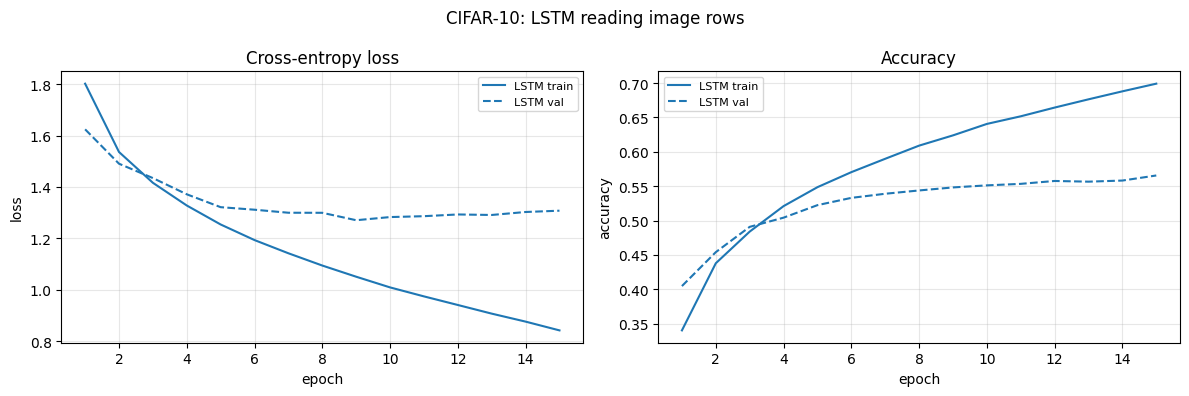

CIFAR-10 test accuracy: 0.5598
              precision    recall  f1-score   support

    airplane      0.590     0.670     0.628      1000
  automobile      0.706     0.643     0.673      1000
        bird      0.442     0.425     0.433      1000
         cat      0.371     0.319     0.343      1000
        deer      0.472     0.500     0.485      1000
         dog      0.466     0.482     0.474      1000
        frog      0.563     0.637     0.598      1000
       horse      0.706     0.568     0.629      1000
        ship      0.664     0.742     0.701      1000
       truck      0.621     0.612     0.617      1000

    accuracy                          0.560     10000
   macro avg      0.560     0.560     0.558     10000
weighted avg      0.560     0.560     0.558     10000



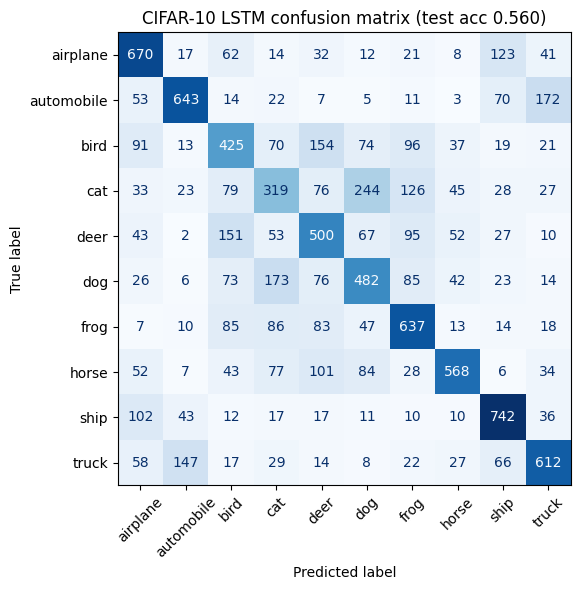

In [ ]:
plot_history({"LSTM": cifar_hist}, "CIFAR-10: LSTM reading image rows", "cifar_curves.png")

cifar_pred, cifar_true = predict(cifar_lstm, cifar_loaders["test"], to_seq=image_to_rows)
cifar_test_acc = (cifar_pred == cifar_true).mean()
print(f"CIFAR-10 test accuracy: {cifar_test_acc:.4f}")
print(classification_report(cifar_true, cifar_pred, target_names=CIFAR_CLASSES, digits=3))
cifar_cm = plot_confusion(cifar_true, cifar_pred, CIFAR_CLASSES,
                          f"CIFAR-10 LSTM confusion matrix (test acc {cifar_test_acc:.3f})",
                          "cifar_confusion.png")

**What to look for (write your observations here after running):**
- Expect test accuracy far below a CNN (a small CNN reaches 75%+; row-wise RNNs typically land around 50–60%).
- Check the confusion matrix for the classic confusions: **cat ↔ dog**, **automobile ↔ truck**, **deer ↔ horse**. These need spatial patterns (shape, texture) that span many rows *and* columns, and an RNN only sees one row at a time and must squeeze everything into its hidden state.
- Compare the train and validation curves: does the model overfit (train keeps improving while validation stalls)?

---
## 3. Part B: Audio MNIST

### 3.1 Download

[Audio MNIST](https://github.com/soerenab/AudioMNIST) has **30,000 recordings**: 60 speakers × 10 digits × 50 repetitions, recorded at 48 kHz. Files are named `{digit}_{speaker}_{repetition}.wav` inside one folder per speaker. The clone is about 1 GB and only needs to happen once.

In [ ]:
AUDIO_REPO = DATA_DIR / "AudioMNIST"
if not (AUDIO_REPO / "data").exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/soerenab/AudioMNIST.git", str(AUDIO_REPO)], check=True)

wav_files = sorted(glob.glob(str(AUDIO_REPO / "data" / "*" / "*.wav")))
print("recordings found:", len(wav_files))
print("example:", Path(wav_files[0]).relative_to(AUDIO_REPO))

recordings found: 30000
example: data/01/0_01_0.wav


### 3.2 From waveform to a sequence of feature vectors

A raw waveform is tens of thousands of numbers per clip, far too long for an RNN to learn from directly. We convert each clip into short overlapping frames:

1. **Resample** to 8 kHz (speech digits keep almost all their information below 4 kHz) and trim leading and trailing silence.
2. **Frame** with a 25 ms window and a 10 ms hop, so one frame is one time step.
3. Compute features per frame:
   - **Mel spectrogram**: energy in 40 frequency bands spaced like human pitch perception (log scale);
   - **MFCC**: a compressed, decorrelated version of the log-mel spectrum (40 coefficients).

Each clip becomes a matrix of shape `(frames, 40)`, about 35–100 frames long. Features are cached to a `.npz` file so this step runs once.

In [ ]:
import librosa

SR, N_FFT, HOP, N_FEAT = 8000, 200, 80, 40     # 25 ms window, 10 ms hop at 8 kHz
FEATURE_TYPE = "mfcc"                          # "mfcc" or "mel"

def extract_features(path, feature_type=FEATURE_TYPE):
    y, _ = librosa.load(path, sr=SR)
    y, _ = librosa.effects.trim(y, top_db=30)
    if feature_type == "mfcc":
        f = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=N_FEAT, n_fft=N_FFT, hop_length=HOP, n_mels=N_FEAT)
    else:
        f = librosa.power_to_db(librosa.feature.melspectrogram(
            y=y, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_FEAT))
    return f.T.astype(np.float32)               # (frames, features): time first

def parse_name(path):
    digit, speaker, _ = Path(path).stem.split("_")
    return int(digit), int(speaker)

cache = DATA_DIR / f"audiomnist_{FEATURE_TYPE}.npz"
if cache.exists():
    z = np.load(cache, allow_pickle=True)
    feats, digits, speakers = list(z["feats"]), z["digits"], z["speakers"]
else:
    feats, digits, speakers = [], [], []
    for p in tqdm(wav_files, desc="extracting features"):
        feats.append(extract_features(p))
        d, s = parse_name(p); digits.append(d); speakers.append(s)
    digits, speakers = np.array(digits), np.array(speakers)
    np.savez(cache, feats=np.array(feats, dtype=object), digits=digits, speakers=speakers)

lengths_all = np.array([f.shape[0] for f in feats])
print(f"{len(feats)} clips | {len(np.unique(speakers))} speakers | feature dim {feats[0].shape[1]}")
print(f"frames per clip: min {lengths_all.min()}, median {int(np.median(lengths_all))}, max {lengths_all.max()}")

extracting features:   0%|          | 0/30000 [00:00<?, ?it/s]

30000 clips | 60 speakers | feature dim 40
frames per clip: min 30, median 63, max 100


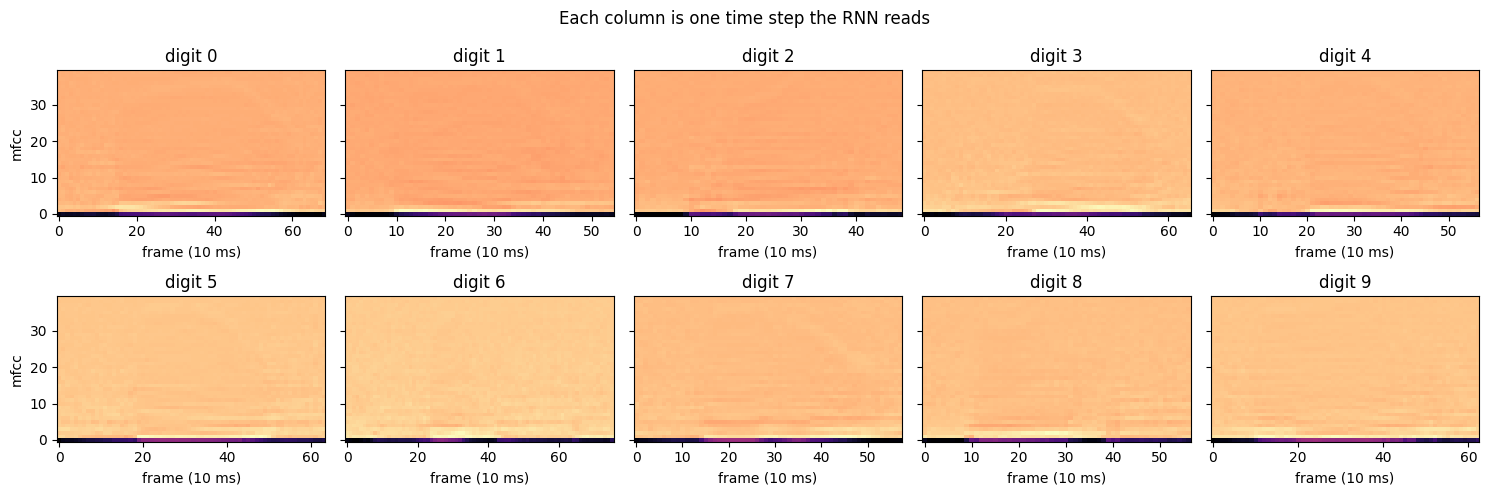

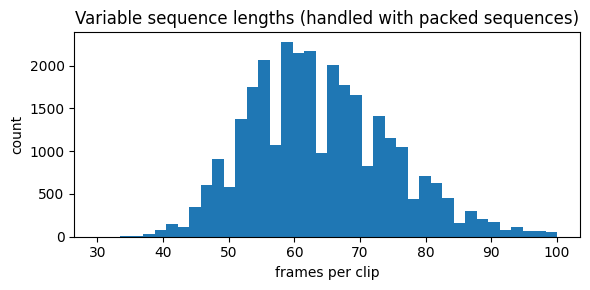

In [ ]:
# Visualise one example of each digit, plus the distribution of sequence lengths
fig, axes = plt.subplots(2, 5, figsize=(15, 5), sharey=True)
for d, ax in enumerate(axes.flat):
    i = int(np.where(digits == d)[0][0])
    ax.imshow(feats[i].T, origin="lower", aspect="auto", cmap="magma")
    ax.set(title=f"digit {d}", xlabel="frame (10 ms)")
axes[0, 0].set_ylabel(FEATURE_TYPE); axes[1, 0].set_ylabel(FEATURE_TYPE)
fig.suptitle("Each column is one time step the RNN reads"); fig.tight_layout()
fig.savefig(FIG_DIR / "audio_features.png", dpi=150); plt.show()

plt.figure(figsize=(6, 3))
plt.hist(lengths_all, bins=40); plt.xlabel("frames per clip"); plt.ylabel("count")
plt.title("Variable sequence lengths (handled with packed sequences)"); plt.tight_layout()
plt.savefig(FIG_DIR / "audio_lengths.png", dpi=150); plt.show()

### 3.3 Speaker-based train / validation / test split

Every speaker says every digit 50 times. With a random clip-level split, the same voices appear in training *and* test, so the model can partly recognize the **speaker** instead of the **digit**, and test accuracy is inflated.

Instead we split by **speaker**: 48 speakers for training, 6 for validation, 6 for test. The test score then measures generalization to **voices the model has never heard**.

Features are standardized (zero mean, unit variance per coefficient) using statistics from the **training speakers only**, so no information leaks from validation or test.

In [ ]:
rng = np.random.default_rng(SEED)
spk = rng.permutation(np.unique(speakers))
n_spk = len(spk)
n_test_spk = n_val_spk = max(1, round(n_spk * 0.1))
test_spk, val_spk, train_spk = spk[:n_test_spk], spk[n_test_spk:n_test_spk + n_val_spk], spk[n_test_spk + n_val_spk:]
assert not (set(train_spk) & set(val_spk) or set(train_spk) & set(test_spk) or set(val_spk) & set(test_spk))
print("test speakers:", sorted(test_spk.tolist()))
print("val speakers: ", sorted(val_spk.tolist()))

idx = {name: np.where(np.isin(speakers, s))[0]
       for name, s in [("train", train_spk), ("val", val_spk), ("test", test_spk)]}

train_stack = np.concatenate([feats[i] for i in idx["train"]])
feat_mean, feat_std = train_stack.mean(0), train_stack.std(0) + 1e-6

class AudioDigits(Dataset):
    def __init__(self, indices):
        self.x = [torch.from_numpy((feats[i] - feat_mean) / feat_std) for i in indices]
        self.y = torch.as_tensor(digits[indices], dtype=torch.long)
    def __len__(self):  return len(self.y)
    def __getitem__(self, i): return self.x[i], self.y[i]

def pad_collate(batch):
    # Pad to the longest clip in the batch and keep the true lengths for packing.
    xs, ys = zip(*batch)
    lengths = torch.tensor([x.shape[0] for x in xs])
    xpad = nn.utils.rnn.pad_sequence(xs, batch_first=True)   # (B, T_max, 40)
    return xpad, lengths, torch.stack(ys)

audio_sets = {k: AudioDigits(v) for k, v in idx.items()}
audio_loaders = {k: DataLoader(ds, BATCH_SIZE, shuffle=(k == "train"), collate_fn=pad_collate)
                 for k, ds in audio_sets.items()}
for k, ds in audio_sets.items():
    print(f"{k:5s}: {len(ds):5d} clips")

xb, lb, yb = next(iter(audio_loaders["train"]))
print("padded batch:", tuple(xb.shape), "| true lengths of first 5:", lb[:5].tolist())

test speakers: [8, 18, 19, 25, 29, 56]
val speakers:  [6, 28, 40, 45, 51, 60]
train: 24000 clips
val  :  3000 clips
test :  3000 clips
padded batch: (128, 99, 40) | true lengths of first 5: [49, 65, 68, 59, 74]


### 3.4 LSTM classifier for spoken digits

Same `SeqClassifier` as for CIFAR-10, with `input_size=40` (one MFCC vector per 10 ms frame) and 128 hidden units.

In [ ]:
set_seed()
audio_lstm = SeqClassifier(input_size=N_FEAT, hidden_size=128, rnn_type="lstm")
print("parameters:", f"{count_params(audio_lstm):,}")
audio_lstm, audio_hist = train_model(audio_lstm, audio_loaders["train"], audio_loaders["val"],
                                     AUDIO_EPOCHS, name="Audio LSTM")
torch.save(audio_lstm.state_dict(), PROJECT_DIR / "audio_lstm.pt")

parameters: 88,330
[Audio LSTM] epoch  1/25  train loss 1.096 acc 0.599 | val loss 0.757 acc 0.736
[Audio LSTM] epoch  2/25  train loss 0.290 acc 0.909 | val loss 0.469 acc 0.859
[Audio LSTM] epoch  3/25  train loss 0.121 acc 0.966 | val loss 0.520 acc 0.871
[Audio LSTM] epoch  4/25  train loss 0.070 acc 0.981 | val loss 0.324 acc 0.925
[Audio LSTM] epoch  5/25  train loss 0.043 acc 0.989 | val loss 0.409 acc 0.908
[Audio LSTM] epoch  6/25  train loss 0.028 acc 0.993 | val loss 0.366 acc 0.929
[Audio LSTM] epoch  7/25  train loss 0.022 acc 0.994 | val loss 0.323 acc 0.930
[Audio LSTM] epoch  8/25  train loss 0.013 acc 0.997 | val loss 0.371 acc 0.932
[Audio LSTM] epoch  9/25  train loss 0.015 acc 0.996 | val loss 0.657 acc 0.867
[Audio LSTM] epoch 10/25  train loss 0.009 acc 0.998 | val loss 0.468 acc 0.922
[Audio LSTM] epoch 11/25  train loss 0.006 acc 0.999 | val loss 0.394 acc 0.934
[Audio LSTM] epoch 12/25  train loss 0.007 acc 0.998 | val loss 0.426 acc 0.920
[Audio LSTM] epoch 13

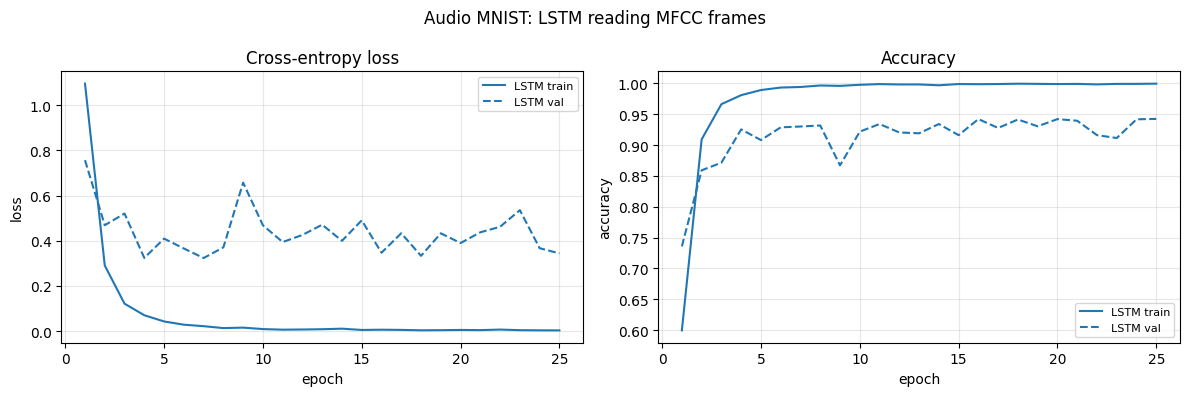

Audio MNIST test accuracy (unseen speakers): 0.9827
              precision    recall  f1-score   support

           0      0.968     0.993     0.980       300
           1      0.980     1.000     0.990       300
           2      0.971     0.990     0.980       300
           3      0.949     0.997     0.972       300
           4      0.997     0.990     0.993       300
           5      0.993     0.977     0.985       300
           6      1.000     0.960     0.980       300
           7      0.986     0.963     0.975       300
           8      0.993     0.957     0.975       300
           9      0.993     1.000     0.997       300

    accuracy                          0.983      3000
   macro avg      0.983     0.983     0.983      3000
weighted avg      0.983     0.983     0.983      3000



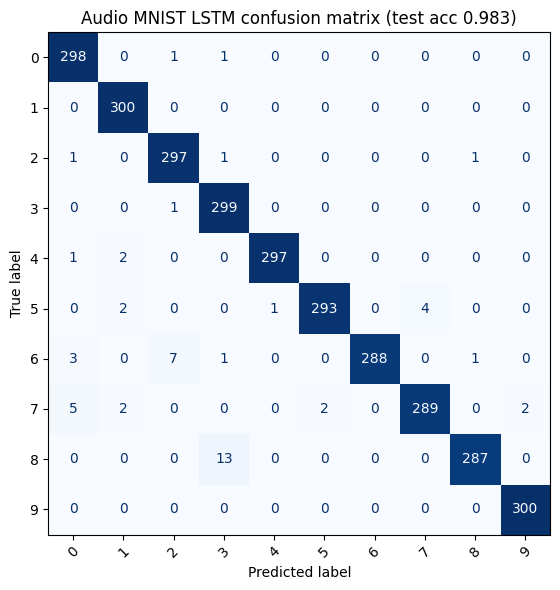

In [ ]:
DIGIT_NAMES = [str(d) for d in range(10)]
plot_history({"LSTM": audio_hist}, "Audio MNIST: LSTM reading MFCC frames", "audio_curves.png")

audio_pred, audio_true = predict(audio_lstm, audio_loaders["test"])
audio_test_acc = (audio_pred == audio_true).mean()
print(f"Audio MNIST test accuracy (unseen speakers): {audio_test_acc:.4f}")
print(classification_report(audio_true, audio_pred, target_names=DIGIT_NAMES, digits=3))
audio_cm = plot_confusion(audio_true, audio_pred, DIGIT_NAMES,
                          f"Audio MNIST LSTM confusion matrix (test acc {audio_test_acc:.3f})",
                          "audio_confusion.png")

**What to look for:** accuracy on unseen speakers should be much higher than on CIFAR-10. Check which digits get confused; pairs that share sounds (for example *one* / *nine*, sharing the "n" sound, or *five* / *nine*, sharing the "ai" vowel) are the usual suspects. Look at per-test-speaker accuracy below: some voices or accents are harder than others.

In [ ]:
test_speaker_ids = speakers[idx["test"]]
print("accuracy per test speaker:")
for s in sorted(np.unique(test_speaker_ids)):
    m = test_speaker_ids == s
    print(f"  speaker {s:02d}: {(audio_pred[m] == audio_true[m]).mean():.3f}")

accuracy per test speaker:
  speaker 08: 0.998
  speaker 18: 0.990
  speaker 19: 0.968
  speaker 25: 0.950
  speaker 29: 0.998
  speaker 56: 0.992


---
## 4. Experiments on Audio MNIST

The experiments run on Audio MNIST only: it trains quickly and has the longest sequences, which is where differences between cell types should show up.

### 4.1 Vanilla RNN vs LSTM vs GRU (hidden size 128)

[Audio RNN] epoch  1/25  train loss 1.314 acc 0.477 | val loss 1.024 acc 0.603
[Audio RNN] epoch  2/25  train loss 0.917 acc 0.634 | val loss 1.074 acc 0.628
[Audio RNN] epoch  3/25  train loss 0.808 acc 0.689 | val loss 0.874 acc 0.698
[Audio RNN] epoch  4/25  train loss 0.762 acc 0.721 | val loss 0.795 acc 0.724
[Audio RNN] epoch  5/25  train loss 0.689 acc 0.751 | val loss 0.864 acc 0.725
[Audio RNN] epoch  6/25  train loss 0.655 acc 0.778 | val loss 0.835 acc 0.746
[Audio RNN] epoch  7/25  train loss 0.606 acc 0.806 | val loss 0.773 acc 0.752
[Audio RNN] epoch  8/25  train loss 0.514 acc 0.841 | val loss 0.708 acc 0.799
[Audio RNN] epoch  9/25  train loss 0.521 acc 0.845 | val loss 0.976 acc 0.754
[Audio RNN] epoch 10/25  train loss 0.512 acc 0.854 | val loss 0.787 acc 0.783
[Audio RNN] epoch 11/25  train loss 0.525 acc 0.852 | val loss 0.933 acc 0.754
[Audio RNN] epoch 12/25  train loss 0.446 acc 0.874 | val loss 0.724 acc 0.800
[Audio RNN] epoch 13/25  train loss 0.422 acc 0.880 

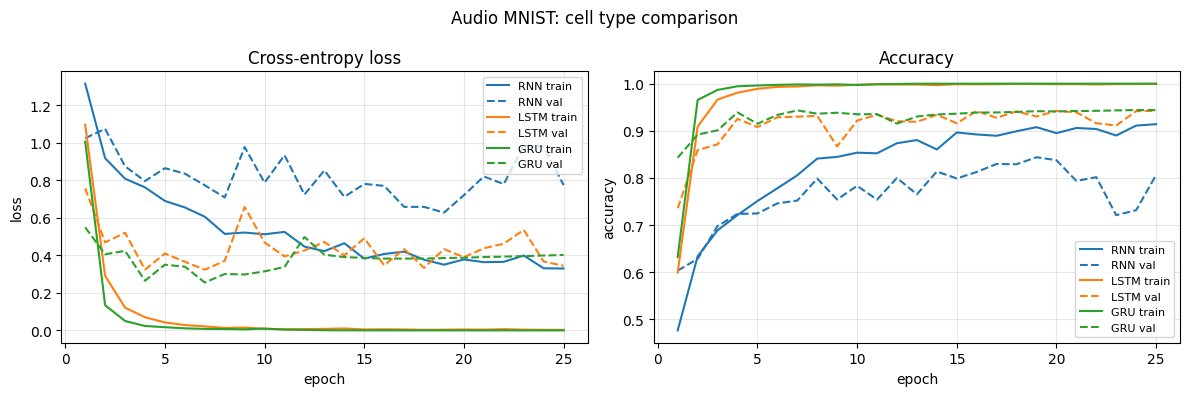

cell      params  best val    test  time (s)
RNN       23,050     0.844   0.836      49.8
LSTM      88,330     0.942   0.983      50.8
GRU       66,570     0.944   0.992      51.1


In [ ]:
cell_results, cell_hists, cell_models = {}, {}, {}
for rnn_type in ["rnn", "lstm", "gru"]:
    set_seed()
    m = SeqClassifier(N_FEAT, 128, rnn_type=rnn_type)
    m, h = train_model(m, audio_loaders["train"], audio_loaders["val"], AUDIO_EPOCHS,
                       name=f"Audio {rnn_type.upper()}")
    p, t = predict(m, audio_loaders["test"])
    cell_hists[rnn_type.upper()] = h
    cell_models[rnn_type.upper()] = m
    cell_results[rnn_type.upper()] = dict(params=count_params(m), best_val=h["best_val_acc"],
                                          test=(p == t).mean(), time_s=h["time_s"])

plot_history(cell_hists, "Audio MNIST: cell type comparison", "audio_cell_comparison.png")
print(f"{'cell':6s} {'params':>9s} {'best val':>9s} {'test':>7s} {'time (s)':>9s}")
for k, r in cell_results.items():
    print(f"{k:6s} {r['params']:9,d} {r['best_val']:9.3f} {r['test']:7.3f} {r['time_s']:9.1f}")

**Expected pattern:** the vanilla RNN learns slower and ends lower, because each clip is roughly 35–100 steps long and the gradient from the final classification has to travel back through all of them (Section 5 measures this). LSTM and GRU reach similar accuracy. GRU has about ¾ of the LSTM's parameters (3 gates vs 4) and is a bit faster per epoch.

### 4.2 Effect of hidden size (LSTM)

[LSTM h=32] epoch  1/25  train loss 1.722 acc 0.349 | val loss 1.179 acc 0.571
[LSTM h=32] epoch  2/25  train loss 0.856 acc 0.672 | val loss 0.966 acc 0.686
[LSTM h=32] epoch  3/25  train loss 0.620 acc 0.767 | val loss 0.833 acc 0.724
[LSTM h=32] epoch  4/25  train loss 0.475 acc 0.830 | val loss 0.883 acc 0.735
[LSTM h=32] epoch  5/25  train loss 0.345 acc 0.900 | val loss 0.856 acc 0.774
[LSTM h=32] epoch  6/25  train loss 0.228 acc 0.943 | val loss 0.701 acc 0.811
[LSTM h=32] epoch  7/25  train loss 0.164 acc 0.959 | val loss 0.666 acc 0.823
[LSTM h=32] epoch  8/25  train loss 0.129 acc 0.968 | val loss 0.579 acc 0.849
[LSTM h=32] epoch  9/25  train loss 0.102 acc 0.975 | val loss 0.593 acc 0.858
[LSTM h=32] epoch 10/25  train loss 0.081 acc 0.980 | val loss 0.616 acc 0.847
[LSTM h=32] epoch 11/25  train loss 0.066 acc 0.984 | val loss 0.584 acc 0.852
[LSTM h=32] epoch 12/25  train loss 0.055 acc 0.986 | val loss 0.566 acc 0.865
[LSTM h=32] epoch 13/25  train loss 0.041 acc 0.991 

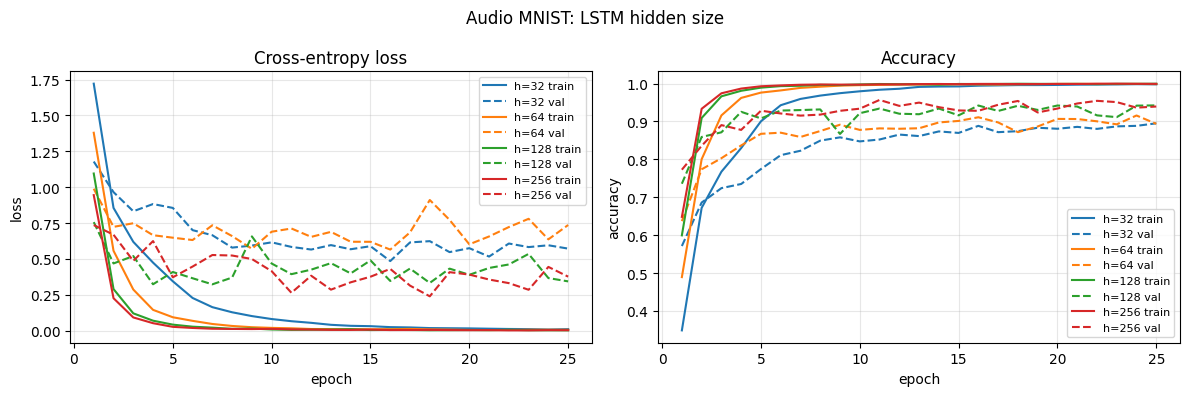

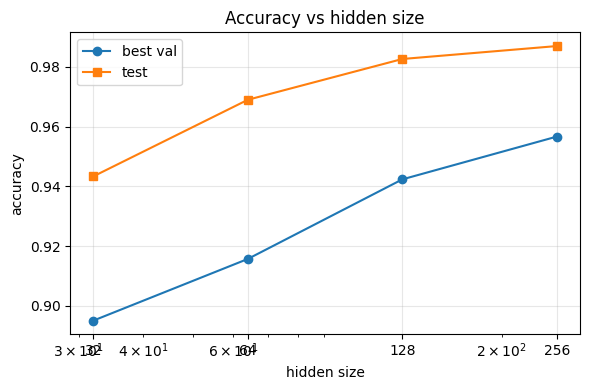

hidden    params  best val    test  time (s)
    32     9,802     0.895   0.943      51.7
    64    27,786     0.916   0.969      53.3
   128    88,330     0.942   0.983      53.6
   256   307,722     0.957   0.987      62.6


In [ ]:
HIDDEN_SIZES = [32, 64, 128, 256]
size_results = {}
size_hists = {}
for hsz in HIDDEN_SIZES:
    set_seed()
    m = SeqClassifier(N_FEAT, hsz, rnn_type="lstm")
    m, h = train_model(m, audio_loaders["train"], audio_loaders["val"], AUDIO_EPOCHS,
                       name=f"LSTM h={hsz}")
    p, t = predict(m, audio_loaders["test"])
    size_hists[f"h={hsz}"] = h
    size_results[hsz] = dict(params=count_params(m), best_val=h["best_val_acc"],
                             test=(p == t).mean(), time_s=h["time_s"])

plot_history(size_hists, "Audio MNIST: LSTM hidden size", "audio_hidden_size.png")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(HIDDEN_SIZES, [size_results[h]["best_val"] for h in HIDDEN_SIZES], "o-", label="best val")
ax.plot(HIDDEN_SIZES, [size_results[h]["test"] for h in HIDDEN_SIZES], "s-", label="test")
ax.set(xscale="log", xticks=HIDDEN_SIZES, xticklabels=HIDDEN_SIZES, xlabel="hidden size",
       ylabel="accuracy", title="Accuracy vs hidden size")
ax.grid(alpha=0.3); ax.legend(); fig.tight_layout()
fig.savefig(FIG_DIR / "audio_hidden_size_acc.png", dpi=150); plt.show()

print(f"{'hidden':>6s} {'params':>9s} {'best val':>9s} {'test':>7s} {'time (s)':>9s}")
for hsz, r in size_results.items():
    print(f"{hsz:6d} {r['params']:9,d} {r['best_val']:9.3f} {r['test']:7.3f} {r['time_s']:9.1f}")

**Interpretation prompts:** does a bigger hidden state keep helping, or does accuracy plateau? Parameter count grows roughly with the *square* of the hidden size ($4h^2$ recurrent weights for an LSTM), so watch for the point where extra capacity stops paying off or the gap between train and validation widens (overfitting to the 48 training voices).

---
## 5. Vanishing gradients, measured directly

During BPTT, the gradient of the loss with respect to an early input $x_t$ is a product of Jacobians across all later steps:

$$\frac{\partial \mathcal{L}}{\partial x_t} = \frac{\partial \mathcal{L}}{\partial h_T}\left(\prod_{k=t+1}^{T}\frac{\partial h_k}{\partial h_{k-1}}\right)\frac{\partial h_t}{\partial x_t}$$

For a vanilla RNN, each factor is $\mathrm{diag}(1 - h_k^2)\,W_{hh}$. If its norm is below 1, the product shrinks **exponentially** with the distance $T - t$, so early time steps barely affect the weight updates and the network "forgets" the beginning of the sequence. The LSTM's additive cell update gives the gradient a path that is not repeatedly squashed.

Below we measure $\lVert \partial \mathcal{L} / \partial x_t \rVert$ for every time step $t$ on the same batch, for two situations:

1. **At initialization** (averaged over 5 random seeds): shows the built-in behaviour of each cell before learning.
2. **After training** (the models from Section 4.1): shows how far back each trained model actually uses its input.

We use audio clips trimmed to a fixed length so every step exists in every example. A flat curve means early steps still receive gradient; a curve that drops toward the left (on a log scale) means vanishing gradients.

gradient probe batch: (256, 63, 40)


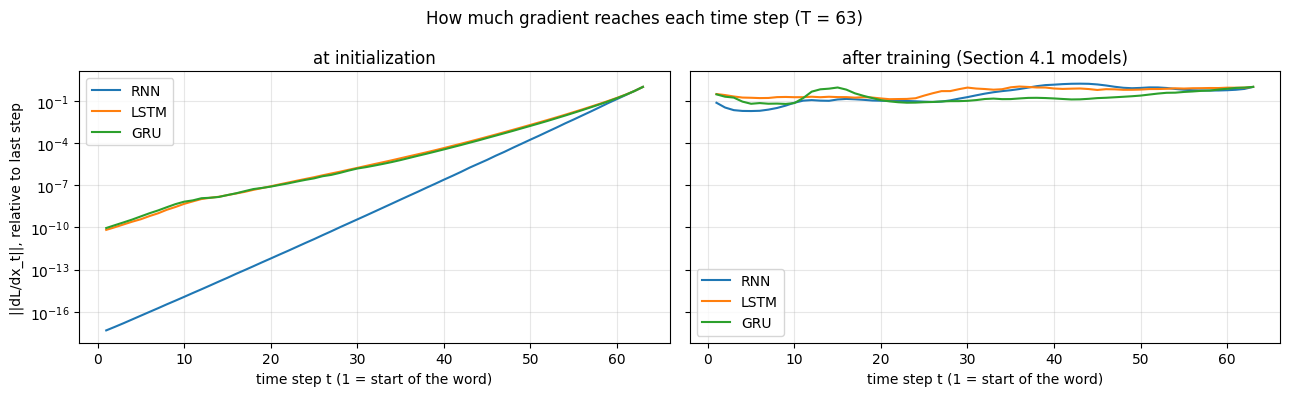

gradient at first step / gradient at last step
cell        init    trained
RNN     4.75e-18   7.44e-02
LSTM    6.72e-11   3.11e-01
GRU     9.10e-11   2.95e-01


In [ ]:
def input_gradient_profile(model, x, y):
    # Per-time-step L2 norm of dLoss/dx_t, averaged over the batch.
    model = model.to(device).train()   # cuDNN RNN backward requires train mode (no dropout is used)
    x = x.clone().to(device).requires_grad_(True)
    loss = nn.functional.cross_entropy(model(x), y.to(device))
    loss.backward()
    return x.grad.norm(dim=2).mean(0).detach().cpu().numpy()

# a batch of clips trimmed / padded to a common length T
T_FIX = int(np.percentile(lengths_all, 50))
cand = [i for i in idx["train"] if lengths_all[i] >= T_FIX]
long_idx = np.random.default_rng(SEED).choice(cand, 256, replace=False)   # random sample across speakers and digits
xg = torch.stack([torch.from_numpy((feats[i][:T_FIX] - feat_mean) / feat_std) for i in long_idx])
yg = torch.as_tensor(digits[long_idx], dtype=torch.long)
print("gradient probe batch:", tuple(xg.shape))

profiles_init, profiles_trained = {}, {}
for rnn_type in ["rnn", "lstm", "gru"]:
    runs = []
    for seed in range(5):                     # average over 5 random initialisations
        set_seed(seed)
        runs.append(input_gradient_profile(SeqClassifier(N_FEAT, 128, rnn_type=rnn_type), xg, yg))
    profiles_init[rnn_type.upper()] = np.mean(runs, axis=0)
    profiles_trained[rnn_type.upper()] = input_gradient_profile(cell_models[rnn_type.upper()], xg, yg)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (title, profs) in zip(axes, [("at initialization", profiles_init),
                                     ("after training (Section 4.1 models)", profiles_trained)]):
    for name, prof in profs.items():
        ax.plot(range(1, T_FIX + 1), prof / prof[-1], label=name)
    ax.set(yscale="log", xlabel="time step t (1 = start of the word)", title=title)
    ax.grid(alpha=0.3, which="both"); ax.legend()
axes[0].set_ylabel("||dL/dx_t||, relative to last step")
fig.suptitle(f"How much gradient reaches each time step (T = {T_FIX})")
fig.tight_layout(); fig.savefig(FIG_DIR / "vanishing_gradients.png", dpi=150); plt.show()

print("gradient at first step / gradient at last step")
print(f"{'cell':5s} {'init':>10s} {'trained':>10s}")
for name in profiles_init:
    pi, pt = profiles_init[name], profiles_trained[name]
    print(f"{name:5s} {pi[0] / pi[-1]:10.2e} {pt[0] / pt[-1]:10.2e}")

**Reading the plot:**
- *At initialization* all three curves fall toward $t = 1$, because every cell starts out "forgetful" (PyTorch initializes the LSTM forget-gate bias at 0, so $f_t \approx 0.5$). The vanilla RNN's decay should be by far the steepest, many more orders of magnitude, because its only path back in time is through repeated `tanh` and $W_{hh}$ multiplications.
- *After training*, compare how much the curves flatten. LSTM and GRU can learn to keep their gates open (forget gate near 1), creating a path along which gradient passes nearly unchanged; the vanilla RNN has no such mechanism. Report the first-step / last-step ratios from the table and relate them to the accuracy gap in Section 4.1.
- If the vanilla RNN mainly receives gradient from the last frames, it effectively classifies the digit from the *end* of the word. That is a concrete statement of the vanishing gradient problem for your report.

Optional extension: repeat the probe on CIFAR-10 rows (`image_to_rows(x0)`, only 32 steps). A shorter sequence gives the decay less room to compound.

---
## 6. Comparison: images vs audio

task                 input dim   seq len  LSTM test acc
CIFAR-10 (rows)             96        32          0.560
Audio MNIST (MFCC)          40    30-100          0.983


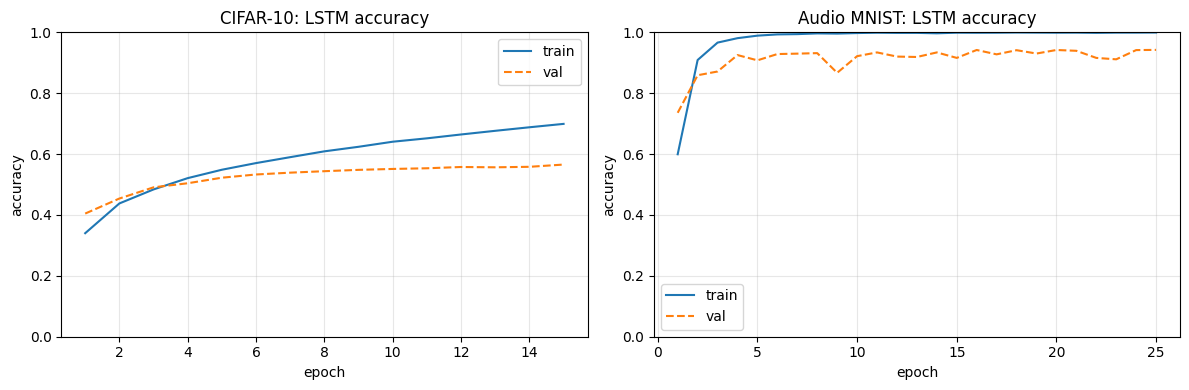

In [ ]:
summary = [
    ("CIFAR-10 (rows)",   96,     32,                          cifar_test_acc),
    ("Audio MNIST (MFCC)", N_FEAT, f"{lengths_all.min()}-{lengths_all.max()}", audio_test_acc),
]
print(f"{'task':20s} {'input dim':>9s} {'seq len':>9s} {'LSTM test acc':>14s}")
for name, dim, L, acc in summary:
    print(f"{name:20s} {dim:9d} {str(L):>9s} {acc:14.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, h) in zip(axes, [("CIFAR-10", cifar_hist), ("Audio MNIST", audio_hist)]):
    ep = range(1, len(h["val_acc"]) + 1)
    ax.plot(ep, h["train_acc"], label="train"); ax.plot(ep, h["val_acc"], "--", label="val")
    ax.set(title=f"{name}: LSTM accuracy", xlabel="epoch", ylabel="accuracy", ylim=(0, 1))
    ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "cifar_vs_audio.png", dpi=150); plt.show()

### Discussion (fill in with your numbers)

**Why the RNN does better on audio than on images.**
- *Order is meaningful in speech.* A spoken digit is a sequence of sounds in a fixed order (/s/ → /ɪ/ → /k/ → /s/ for "six"). The RNN's inductive bias, processing one step at a time and carrying a summary forward, matches how the data was generated.
- *Order is arbitrary in images.* Reading rows top to bottom is one choice among many. Object identity depends on 2-D local patterns (edges, textures, shapes) that cut across rows. The RNN must remember row 3 until row 25 to connect them, and it has no built-in notion of "pixels next to each other in the same column." A CNN's convolution and pooling encode exactly that spatial locality and translation invariance, which is why CNNs win on CIFAR-10.
- *Task difficulty also differs.* CIFAR-10 has large intra-class variation (many breeds of dog, poses, backgrounds); 10 spoken digits are acoustically distinct. Part of the gap is the dataset, not only the architecture. Say this in the report so the comparison is fair.

**Cell types (Section 4.1) and vanishing gradients (Section 5).** Connect the accuracy and training-speed differences to the gradient profiles: the vanilla RNN's gradient decays exponentially with distance, so it learns mainly from the last frames; gates in LSTM/GRU preserve gradient flow across the 35–100 audio frames.

**Hidden size (Section 4.2).** Describe where accuracy saturates and what that says about how much information is needed to summarize a one-second word.

**Limitations and possible next steps.** Only one seed per configuration; a bidirectional LSTM (reads the word in both directions) or a CNN on spectrograms would likely do even better on audio; data augmentation (noise, time shift) could improve robustness to new speakers.

### Saved outputs

In [ ]:
for f in sorted(FIG_DIR.glob("*.png")):
    print(f)
print("models:", [str(p) for p in PROJECT_DIR.glob("*.pt")])

/content/drive/MyDrive/rnn_midterm/figures/audio_cell_comparison.png
/content/drive/MyDrive/rnn_midterm/figures/audio_confusion.png
/content/drive/MyDrive/rnn_midterm/figures/audio_curves.png
/content/drive/MyDrive/rnn_midterm/figures/audio_features.png
/content/drive/MyDrive/rnn_midterm/figures/audio_hidden_size.png
/content/drive/MyDrive/rnn_midterm/figures/audio_hidden_size_acc.png
/content/drive/MyDrive/rnn_midterm/figures/audio_lengths.png
/content/drive/MyDrive/rnn_midterm/figures/cifar_as_sequence.png
/content/drive/MyDrive/rnn_midterm/figures/cifar_confusion.png
/content/drive/MyDrive/rnn_midterm/figures/cifar_curves.png
/content/drive/MyDrive/rnn_midterm/figures/cifar_vs_audio.png
/content/drive/MyDrive/rnn_midterm/figures/vanishing_gradients.png
models: ['/content/drive/MyDrive/rnn_midterm/cifar_lstm.pt', '/content/drive/MyDrive/rnn_midterm/audio_lstm.pt']
